# Perceptron Lab
**Name:** Syed Ashtar Ali Zaidi  
**Reg no:** FA23-BAI-049

**Dataset:** Iris (UCI Machine Learning Repository). To make it a binary problem for a perceptron, we use two classes (*Setosa* vs *Versicolor*) and two features (*petal length*, *petal width*) so we can plot it in 2D.

## Lab Task 1: Load and Visualize the Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = [iris.target_names[i] for i in iris.target]
print("Full dataset shape:", df.shape)
df.head()

Full dataset shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


X shape: (100, 2) | y shape: (100,)
Class counts: [50 50]


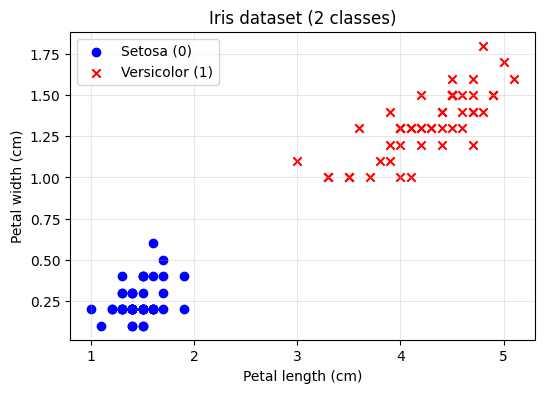

In [2]:
# Keep only 2 classes (Setosa=0, Versicolor=1) and 2 features
df2 = df[df['species'].isin(['setosa', 'versicolor'])]
X = df2[['petal length (cm)', 'petal width (cm)']].values
y = np.where(df2['species'] == 'setosa', 0, 1)

print("X shape:", X.shape, "| y shape:", y.shape)
print("Class counts:", np.bincount(y))

# Visualize
plt.figure(figsize=(6,4))
plt.scatter(X[y==0,0], X[y==0,1], c='blue', label='Setosa (0)')
plt.scatter(X[y==1,0], X[y==1,1], c='red', marker='x', label='Versicolor (1)')
plt.xlabel('Petal length (cm)'); plt.ylabel('Petal width (cm)')
plt.title('Iris dataset (2 classes)'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Lab Task 2: Perceptron Implementation and Training

**Perceptron rule:**
- Output: ŷ = 1 if (w·x + b) ≥ 0, else 0
- Update for each sample: w = w + η (y − ŷ) x,  b = b + η (y − ŷ)

In [3]:
class Perceptron:
    def __init__(self, lr=0.1, epochs=20):
        self.lr, self.epochs = lr, epochs

    def predict(self, X):
        return np.where(X @ self.w + self.b >= 0, 1, 0)

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        self.errors = []                      # misclassifications per epoch
        for _ in range(self.epochs):
            errs = 0
            for xi, target in zip(X, y):
                update = self.lr * (target - self.predict(xi.reshape(1, -1))[0])
                self.w += update * xi
                self.b += update
                errs += int(update != 0)
            self.errors.append(errs)
        return self

In [4]:
# Train / test split (80/20)
rng = np.random.default_rng(42)
idx = rng.permutation(len(X))
split = int(0.8 * len(X))
X_train, X_test = X[idx[:split]], X[idx[split:]]
y_train, y_test = y[idx[:split]], y[idx[split:]]

model = Perceptron(lr=0.1, epochs=20).fit(X_train, y_train)

print("Learned weights:", model.w)
print("Learned bias   :", model.b)
print("Train accuracy :", np.mean(model.predict(X_train) == y_train))
print("Test accuracy  :", np.mean(model.predict(X_test) == y_test))

Learned weights: [0.13 0.22]
Learned bias   : -0.5
Train accuracy : 1.0
Test accuracy  : 1.0


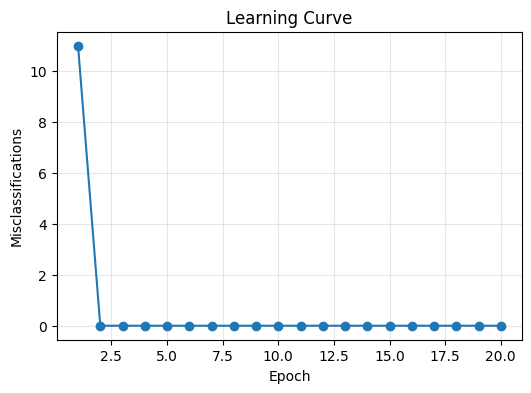

In [5]:
# Learning curve
plt.figure(figsize=(6,4))
plt.plot(range(1, len(model.errors)+1), model.errors, marker='o')
plt.xlabel('Epoch'); plt.ylabel('Misclassifications')
plt.title('Learning Curve'); plt.grid(alpha=0.3)
plt.show()

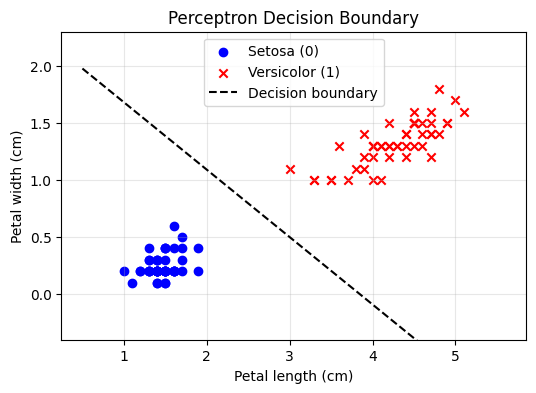

In [6]:
# Decision boundary: w1*x1 + w2*x2 + b = 0
plt.figure(figsize=(6,4))
plt.scatter(X[y==0,0], X[y==0,1], c='blue', label='Setosa (0)')
plt.scatter(X[y==1,0], X[y==1,1], c='red', marker='x', label='Versicolor (1)')
x1 = np.linspace(X[:,0].min()-0.5, X[:,0].max()+0.5, 100)
x2 = -(model.w[0]*x1 + model.b) / model.w[1]
plt.plot(x1, x2, 'k--', label='Decision boundary')
plt.ylim(X[:,1].min()-0.5, X[:,1].max()+0.5)
plt.xlabel('Petal length (cm)'); plt.ylabel('Petal width (cm)')
plt.title('Perceptron Decision Boundary'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Conclusion
The two Iris classes are linearly separable, so the perceptron converges: the errors per epoch drop to 0 (learning curve) and the learned weights define a straight line that separates the classes.